# РАЗ 1. Метрический классификатор

В работе выполнены задания из методических материалов: вычисление метрик расстояния,
нормализация, ручная классификация фильмов методами k ближайших соседей и парзеновского
окна, а также построение и сравнение моделей на наборе `diabetes_data.csv`.

In [1]:
from pathlib import Path
from itertools import combinations
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import distance
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    pairwise_distances,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier, KernelDensity
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
DATA_PATH = Path("diabetes_data.csv")

## 1. Евклидово расстояние между фильмами

Расстояния вычисляются тремя способами: `math.dist`, `numpy.linalg.norm` и
`scipy.spatial.distance.euclidean`. Перед вычислением проверяется совпадение размерностей.

In [2]:
movie_names = ["Avatar", "Titanic", "The Dark Knight"]
movies = np.array([
    [162, 2009, 237_000_000],
    [194, 1997, 200_000_000],
    [152, 2008, 185_000_000],
], dtype=float)

def validate_vectors(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    if a.ndim != 1 or b.ndim != 1:
        raise ValueError("Каждая точка должна быть одномерным вектором")
    if a.shape != b.shape:
        raise ValueError(f"Размерности не совпадают: {a.shape} и {b.shape}")
    return a, b

def euclidean_math(a, b):
    a, b = validate_vectors(a, b)
    return math.dist(a, b)

def euclidean_numpy(a, b):
    a, b = validate_vectors(a, b)
    return float(np.linalg.norm(a - b))

def euclidean_scipy(a, b):
    a, b = validate_vectors(a, b)
    return float(distance.euclidean(a, b))

def pairwise_table(data, names, metric_function):
    matrix = np.zeros((len(data), len(data)), dtype=float)
    for i, j in combinations(range(len(data)), 2):
        matrix[i, j] = matrix[j, i] = metric_function(data[i], data[j])
    return pd.DataFrame(matrix, index=names, columns=names)

euclidean_tables = {
    "math.dist": pairwise_table(movies, movie_names, euclidean_math),
    "numpy.linalg.norm": pairwise_table(movies, movie_names, euclidean_numpy),
    "scipy.euclidean": pairwise_table(movies, movie_names, euclidean_scipy),
}

for method, table in euclidean_tables.items():
    print(f"\n{method}")
    display(table.round(3))

assert np.allclose(euclidean_tables["math.dist"], euclidean_tables["numpy.linalg.norm"])
assert np.allclose(euclidean_tables["math.dist"], euclidean_tables["scipy.euclidean"])

pairs = [
    (euclidean_math(movies[i], movies[j]), movie_names[i], movie_names[j])
    for i, j in combinations(range(len(movies)), 2)
]
closest_euclidean = min(pairs)
print("Наиболее похожая пара по сырым данным:", closest_euclidean[1:], "расстояние =", closest_euclidean[0])


math.dist


,Avatar,Titanic,The Dark Knight
Avatar,0.0,37000000.0,52000000.0
Titanic,37000000.0,0.0,15000000.0
The Dark Knight,52000000.0,15000000.0,0.0



numpy.linalg.norm


,Avatar,Titanic,The Dark Knight
Avatar,0.0,37000000.0,52000000.0
Titanic,37000000.0,0.0,15000000.0
The Dark Knight,52000000.0,15000000.0,0.0



scipy.euclidean


,Avatar,Titanic,The Dark Knight
Avatar,0.0,37000000.0,52000000.0
Titanic,37000000.0,0.0,15000000.0
The Dark Knight,52000000.0,15000000.0,0.0


Наиболее похожая пара по сырым данным: ('Titanic', 'The Dark Knight') расстояние = 15000000.000062833


На сырых данных результат почти полностью определяется бюджетом. Это демонстрирует,
почему перед метрической классификацией признаки необходимо масштабировать.

## 2. Манхэттенское расстояние

Реализованы три варианта: SciPy, NumPy и `pairwise_distances` из scikit-learn.

In [3]:
def manhattan_scipy(a, b):
    a, b = validate_vectors(a, b)
    return float(distance.cityblock(a, b))

def manhattan_numpy(a, b):
    a, b = validate_vectors(a, b)
    return float(np.abs(a - b).sum())

manhattan_scipy_table = pairwise_table(movies, movie_names, manhattan_scipy)
manhattan_numpy_table = pairwise_table(movies, movie_names, manhattan_numpy)
manhattan_sklearn_table = pd.DataFrame(
    pairwise_distances(movies, metric="manhattan"),
    index=movie_names,
    columns=movie_names,
)

print("SciPy:")
display(manhattan_scipy_table)
print("NumPy:")
display(manhattan_numpy_table)
print("scikit-learn:")
display(manhattan_sklearn_table)
assert np.allclose(manhattan_scipy_table, manhattan_numpy_table)
assert np.allclose(manhattan_scipy_table, manhattan_sklearn_table)

SciPy:


,Avatar,Titanic,The Dark Knight
Avatar,0.0,37000044.0,52000011.0
Titanic,37000044.0,0.0,15000053.0
The Dark Knight,52000011.0,15000053.0,0.0


NumPy:


,Avatar,Titanic,The Dark Knight
Avatar,0.0,37000044.0,52000011.0
Titanic,37000044.0,0.0,15000053.0
The Dark Knight,52000011.0,15000053.0,0.0


scikit-learn:


,Avatar,Titanic,The Dark Knight
Avatar,0.0,37000044.0,52000011.0
Titanic,37000044.0,0.0,15000053.0
The Dark Knight,52000011.0,15000053.0,0.0


## 3. Расстояние Чебышева

In [4]:
def chebyshev_distance(a, b):
    a, b = validate_vectors(a, b)
    return float(np.max(np.abs(a - b)))

chebyshev_table = pairwise_table(movies, movie_names, chebyshev_distance)
display(chebyshev_table)

,Avatar,Titanic,The Dark Knight
Avatar,0.0,37000000.0,52000000.0
Titanic,37000000.0,0.0,15000000.0
The Dark Knight,52000000.0,15000000.0,0.0


## 4. Min-Max и z-нормализация

Функции принимают матрицу признаков и возвращают нормализованные значения.
После масштабирования сравниваются евклидовы расстояния между фильмами.

In [5]:
def normalize_minmax(data):
    return MinMaxScaler().fit_transform(np.asarray(data, dtype=float))

def normalize_z(data):
    return StandardScaler().fit_transform(np.asarray(data, dtype=float))

movies_minmax = normalize_minmax(movies)
movies_z = normalize_z(movies)

comparison = []
for i, j in combinations(range(len(movies)), 2):
    comparison.append({
        "Пара": f"{movie_names[i]} — {movie_names[j]}",
        "Без нормализации": euclidean_numpy(movies[i], movies[j]),
        "Min-Max": euclidean_numpy(movies_minmax[i], movies_minmax[j]),
        "Z-нормализация": euclidean_numpy(movies_z[i], movies_z[j]),
    })

distance_comparison = pd.DataFrame(comparison)
display(distance_comparison.round(4))

,Пара,Без нормализации,Min-Max,Z-нормализация
0,Avatar — Titanic,3.700000e+07,1.4446,3.3061
1,Avatar — The Dark Knight,5.200000e+07,1.0313,2.4510
2,Titanic — The Dark Knight,1.500000e+07,1.3869,3.1721


**Вывод:** без нормализации бюджет подавляет вклад длительности и года выпуска.
Min-Max приводит признаки к диапазону `[0, 1]`, а z-нормализация выражает их через
число стандартных отклонений. Поэтому после масштабирования сравнение фильмов становится
содержательнее, хотя порядок соседей может зависеть от выбранного способа.

## 5. Ручной kNN для фильмов с евклидовой метрикой

Цель — определить класс фильма `Interstellar`. Для воспроизведения примера из PDF
нормализация выполняется по всем пяти фильмам.

In [6]:
film_df = pd.DataFrame({
    "Фильм": ["Avatar", "Titanic", "The Dark Knight", "Inception", "Interstellar"],
    "Длительность": [162, 194, 152, 148, 169],
    "Год": [2009, 1997, 2008, 2010, 2014],
    "Бюджет": [237, 200, 185, 160, 165],
    "Класс": [1, 0, 1, 1, np.nan],
})

features = ["Длительность", "Год", "Бюджет"]
film_scaled = MinMaxScaler().fit_transform(film_df[features])
train_x, test_x = film_scaled[:4], film_scaled[4]
train_y = film_df.loc[:3, "Класс"].astype(int).to_numpy()

euclidean_to_interstellar = np.linalg.norm(train_x - test_x, axis=1)
neighbors = pd.DataFrame({
    "Фильм": film_df.loc[:3, "Фильм"],
    "Евклидово расстояние": euclidean_to_interstellar,
    "Класс": train_y,
}).sort_values("Евклидово расстояние")
display(neighbors)

for k in (1, 3):
    selected = neighbors.head(k)
    predicted = int(selected["Класс"].value_counts().idxmax())
    print(f"k={k}: класс Interstellar = {predicted}")

,Фильм,Евклидово расстояние,Класс
3,Inception,0.517679,1
2,The Dark Knight,0.573246,1
0,Avatar,0.991972,1
1,Titanic,1.225553,0


k=1: класс Interstellar = 1
k=3: класс Interstellar = 1


## 6. Ручное парзеновское окно для фильмов

Используется прямоугольное ядро и евклидово расстояние. При `h=0.7` учитываются
только объекты, попавшие внутрь окна.

In [7]:
h_movie = 0.7
inside_window = neighbors[neighbors["Евклидово расстояние"] <= h_movie].copy()
display(inside_window)

if inside_window.empty:
    parzen_movie_class = None
else:
    parzen_movie_class = int(inside_window["Класс"].value_counts().idxmax())

print(f"Парзеновское окно, h={h_movie}: класс Interstellar = {parzen_movie_class}")

,Фильм,Евклидово расстояние,Класс
3,Inception,0.517679,1
2,The Dark Knight,0.573246,1


Парзеновское окно, h=0.7: класс Interstellar = 1


## 7. Данные о диабете

В качестве самостоятельного набора данных выбран предоставленный набор диабета.
Целевая переменная `Outcome`: `1` — диабет выявлен, `0` — не выявлен.

Нулевые значения в физиологических показателях (`Glucose`, `BloodPressure`,
`SkinThickness`, `Insulin`, `BMI`) физически означают пропуски. Они заменяются на `NaN`,
а медианная импутация и стандартизация обучаются только на тренировочных данных внутри
pipeline, что предотвращает утечку данных.

In [8]:
diabetes = pd.read_csv(DATA_PATH)
print("Размер:", diabetes.shape)
display(diabetes.head())
display(diabetes["Outcome"].value_counts().rename("Количество").to_frame())

X = diabetes.drop(columns="Outcome").copy()
y = diabetes["Outcome"].astype(int)

zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
X[zero_as_missing] = X[zero_as_missing].replace(0, np.nan)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=RANDOM_STATE,
)
print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

Размер: (767, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


,Количество
Outcome,
0,499
1,268


Обучающая выборка: (575, 8)
Тестовая выборка: (192, 8)


## 8. Подбор числа соседей и модель kNN

Количество соседей выбирается по средней accuracy пятифолдовой стратифицированной
кросс-валидации на обучающей части. Тестовая выборка используется только для итоговой оценки.

Лучшее k: 19
Средняя CV accuracy: 0.7860869565217391


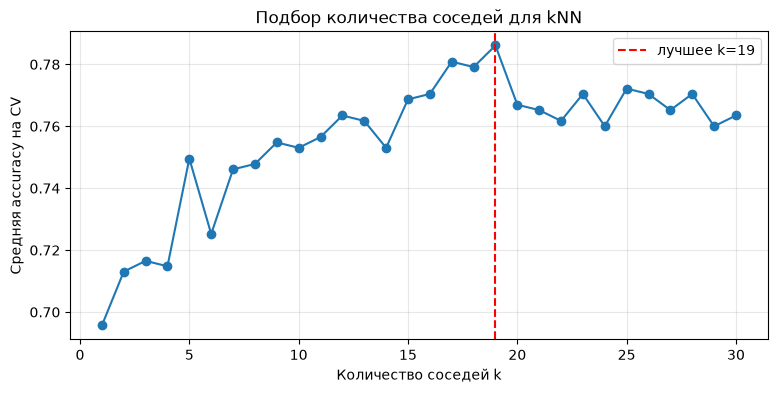

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
k_values = list(range(1, 31))
k_cv_scores = []

for k in k_values:
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=k, metric="euclidean")),
    ])
    score = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy").mean()
    k_cv_scores.append(score)

best_k = k_values[int(np.argmax(k_cv_scores))]
print("Лучшее k:", best_k)
print("Средняя CV accuracy:", max(k_cv_scores))

plt.figure(figsize=(9, 4))
plt.plot(k_values, k_cv_scores, marker="o")
plt.axvline(best_k, color="red", linestyle="--", label=f"лучшее k={best_k}")
plt.xlabel("Количество соседей k")
plt.ylabel("Средняя accuracy на CV")
plt.title("Подбор количества соседей для kNN")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

Тестовая accuracy kNN: 0.7500
              precision    recall  f1-score   support

           0     0.7730    0.8720    0.8195       125
           1     0.6863    0.5224    0.5932        67

    accuracy                         0.7500       192
   macro avg     0.7297    0.6972    0.7064       192
weighted avg     0.7428    0.7500    0.7406       192



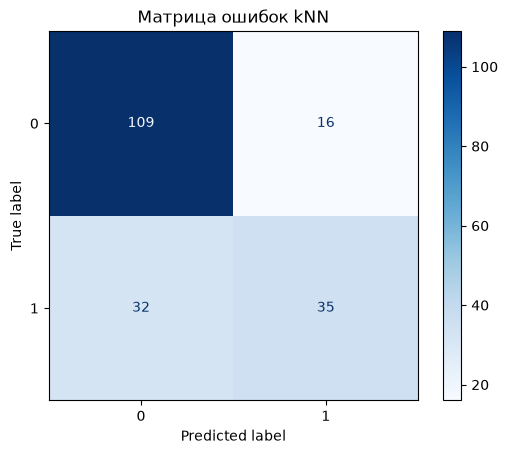

In [10]:
knn_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=best_k, metric="euclidean")),
])
knn_model.fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_test)
accuracy_knn = accuracy_score(y_test, y_pred_knn)

print(f"Тестовая accuracy kNN: {accuracy_knn:.4f}")
print(classification_report(y_test, y_pred_knn, digits=4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_knn, cmap="Blues")
plt.title("Матрица ошибок kNN")
plt.show()

## 9. Парзеновское окно: подбор ширины `h`

Для каждого класса строится отдельная оценка плотности `KernelDensity` с гауссовым
ядром. При прогнозировании выбирается класс с максимальной суммой логарифма плотности
и логарифма априорной вероятности класса.

Лучшая ширина окна h: 1.0
Средняя CV accuracy: 0.7617391304347827


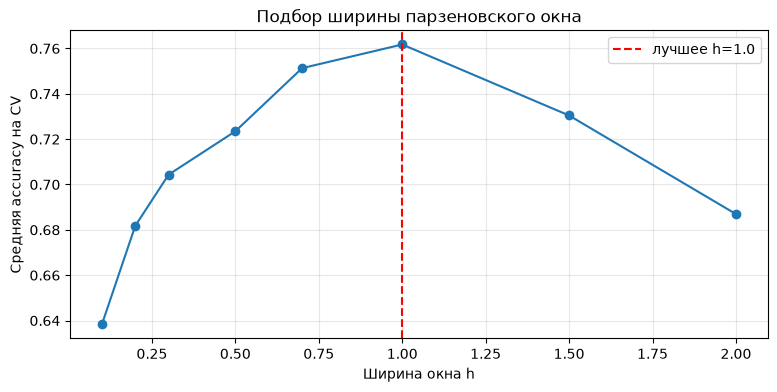

In [11]:
def fit_parzen_models(x_train, y_train, bandwidth):
    classes, counts = np.unique(y_train, return_counts=True)
    models = {}
    log_priors = {}
    for cls, count in zip(classes, counts):
        model = KernelDensity(bandwidth=bandwidth, kernel="gaussian")
        model.fit(x_train[y_train == cls])
        models[cls] = model
        log_priors[cls] = np.log(count / len(y_train))
    return models, log_priors

def predict_parzen(models, log_priors, x_test):
    classes = np.array(sorted(models))
    scores = np.column_stack([
        models[cls].score_samples(x_test) + log_priors[cls]
        for cls in classes
    ])
    return classes[np.argmax(scores, axis=1)]

bandwidths = [0.1, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0]
bandwidth_scores = []

for bandwidth in bandwidths:
    fold_scores = []
    for train_idx, valid_idx in cv.split(X_train, y_train):
        fold_x_train = X_train.iloc[train_idx]
        fold_x_valid = X_train.iloc[valid_idx]
        fold_y_train = y_train.iloc[train_idx].to_numpy()
        fold_y_valid = y_train.iloc[valid_idx].to_numpy()

        imputer = SimpleImputer(strategy="median")
        scaler = StandardScaler()
        transformed_train = scaler.fit_transform(imputer.fit_transform(fold_x_train))
        transformed_valid = scaler.transform(imputer.transform(fold_x_valid))

        models, priors = fit_parzen_models(transformed_train, fold_y_train, bandwidth)
        predictions = predict_parzen(models, priors, transformed_valid)
        fold_scores.append(accuracy_score(fold_y_valid, predictions))

    bandwidth_scores.append(np.mean(fold_scores))

best_h = bandwidths[int(np.argmax(bandwidth_scores))]
print("Лучшая ширина окна h:", best_h)
print("Средняя CV accuracy:", max(bandwidth_scores))

plt.figure(figsize=(9, 4))
plt.plot(bandwidths, bandwidth_scores, marker="o")
plt.axvline(best_h, color="red", linestyle="--", label=f"лучшее h={best_h}")
plt.xlabel("Ширина окна h")
plt.ylabel("Средняя accuracy на CV")
plt.title("Подбор ширины парзеновского окна")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

Тестовая accuracy Парзена: 0.7292
              precision    recall  f1-score   support

           0     0.7417    0.8960    0.8116       125
           1     0.6829    0.4179    0.5185        67

    accuracy                         0.7292       192
   macro avg     0.7123    0.6570    0.6651       192
weighted avg     0.7212    0.7292    0.7093       192



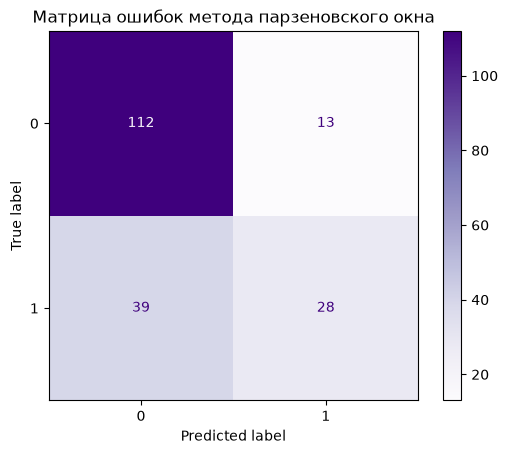

In [12]:
final_imputer = SimpleImputer(strategy="median")
final_scaler = StandardScaler()
X_train_scaled = final_scaler.fit_transform(final_imputer.fit_transform(X_train))
X_test_scaled = final_scaler.transform(final_imputer.transform(X_test))

parzen_models, parzen_priors = fit_parzen_models(X_train_scaled, y_train.to_numpy(), best_h)
y_pred_parzen = predict_parzen(parzen_models, parzen_priors, X_test_scaled)
accuracy_parzen = accuracy_score(y_test, y_pred_parzen)

print(f"Тестовая accuracy Парзена: {accuracy_parzen:.4f}")
print(classification_report(y_test, y_pred_parzen, digits=4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_parzen, cmap="Purples")
plt.title("Матрица ошибок метода парзеновского окна")
plt.show()

## 10. Сравнение итоговых моделей

In [13]:
model_comparison = pd.DataFrame({
    "Модель": [f"kNN, k={best_k}", f"Парзен, h={best_h}"],
    "Accuracy на тесте": [accuracy_knn, accuracy_parzen],
}).sort_values("Accuracy на тесте", ascending=False)
display(model_comparison.round(4))

,Модель,Accuracy на тесте
0,"kNN, k=19",0.7500
1,"Парзен, h=1.0",0.7292


## 11. Ответы на контрольные вопросы

1. **Метрика расстояния** — функция, сопоставляющая каждой паре объектов неотрицательное
   число, характеризующее различие между ними.
2. **Свойства метрики:** неотрицательность; равенство нулю только для совпадающих объектов;
   симметрия; неравенство треугольника.
3. **Евклидово расстояние** — L2-норма разности векторов:
   $d(x,y)=\sqrt{\sum_i(x_i-y_i)^2}$.
4. **Манхэттенское расстояние** — L1-норма:
   $d(x,y)=\sum_i|x_i-y_i|$.
5. **Метрика Минковского** обобщает L1 и L2:
   $d_p(x,y)=(\sum_i|x_i-y_i|^p)^{1/p}$ при $p\geq1$.
6. **Метрический классификатор** определяет класс объекта по классам близких к нему
   обучающих объектов с использованием выбранной метрики.
7. **Метод ближайшего соседа (1-NN)** присваивает новому объекту класс единственного
   ближайшего объекта обучающей выборки.
8. **Метод k ближайших соседей** выбирает `k` ближайших объектов и обычно присваивает
   класс по большинству голосов. `k` является гиперпараметром.
9. **Метод парзеновских окон** взвешивает обучающие объекты с помощью ядра, зависящего
   от расстояния и ширины окна `h`. Малое `h` повышает риск переобучения, большое —
   недообучения.

## Вывод

Все признаки перед метрической классификацией были приведены к сопоставимому масштабу.
Гиперпараметры `k` и `h` выбраны только на обучающей выборке с кросс-валидацией,
а итоговое качество оценено на отдельной тестовой выборке. Это обеспечивает более честное
сравнение kNN и метода парзеновского окна.